# 00 · Pipeline: la base operacional del laboratorio de catas

> **Qué haces tú en este cuaderno:** nada más que darle al play (**Ejecutar todo**, o **Shift + Enter** celda a celda).
> No hay código que escribir ni que editar. Lo que importa es **leer lo que sale** debajo de cada celda; el texto te dice qué mirar.

## Antes de empezar: qué vamos a construir en estos cinco cuadernos

**El problema.** Un laboratorio de catas de café recibe lotes de distintos países. Cada lote se **cata** (diez notas que suman una
puntuación total) y, si llega a **80 puntos o más**, se considera **café de especialidad**. Catar cuesta tiempo y dinero.

**La pregunta de negocio**, escrita de forma que un modelo pueda responderla:

> Dado un lote que **acaba de llegar** (origen, variedad, método de beneficio y análisis del grano verde), **antes de catarlo**,
> ¿qué probabilidad hay de que alcance el grado de especialidad (>= 80 puntos)?

Es una **clasificación binaria**: la respuesta real es sí (`y = 1`) o no (`y = 0`). El modelo contesta con una **probabilidad** entre 0 y 1.
Con ella el negocio decide, por ejemplo, qué lotes catar primero.

**Una trampa que veremos con datos reales.** Las diez notas de la cata **suman** la puntuación total. Un modelo que use las notas
«acertaría» casi siempre... pero no sirve: las notas **no existen** hasta catar el lote. Eso se llama **fuga de información** y lo
mediremos en el cuaderno 03.

**El dato.** Dos archivos CSV públicos del *Coffee Quality Institute* (CQI): arábica y robusta. Son una copia exacta de un repositorio
público; en `references/fuente.md` está su origen y su licencia.

## El mapa de los cuadernos

| Cuaderno | Objetivo | Lee de | Escribe en | Pregunta que responde |
|---|---|---|---|---|
| **00 · operacional** | Simular el sistema del laboratorio | los dos CSV | `cqi.db`: `lotes`, `catas`, `notas_cata`... | ¿Cómo guarda el negocio sus lotes y catas? |
| **01 · RAW → MASTER** | Ingerir lo operacional sin tocarlo (RAW) y depurarlo (MASTER) | `cqi.db` | `cafe.db`: `raw_*`, `master_*` | ¿Qué llegó? ¿Qué es correcto? |
| **02 · MASTER → FS** | Calcular las variables de cada lote | `master_lotes` | `fs_lote`, `fs_catalogo` | ¿Qué sabemos de cada lote **al recibirlo**? |
| **03 · FS → ML** | Añadir el objetivo `y` y repartir en train / valid / test **por tiempo** | `fs_lote`, `master_lotes` | `ml_dataset`, `ml_particiones` | ¿Con qué se entrena y con qué se evalúa? ¿Qué es una fuga? |
| **04 · Entrenamiento** | Entrenar, comparar y registrar el modelo | `ml_dataset` | `models/`, `reports/`, MLflow | ¿Qué tal funciona y cómo se guarda? |

Los cuadernos se ejecutan **en orden**: cada uno usa lo que dejó el anterior. Hacen **lo mismo que las órdenes de la terminal**
(`python -m cafe_mlops.pipeline ...`): aquí lo ves paso a paso y con explicaciones.

### Las capas de datos

| Capa | Qué contiene | Se parece a... |
|---|---|---|
| **Operacional** | El sistema que usa el laboratorio: tablas normalizadas, con claves | el sistema real del negocio |
| **RAW** | Copia **fiel** de lo que llegó, sin corregir nada | un cuaderno de registro |
| **MASTER** | Dato **depurado**: fechas bien escritas, valores imposibles apartados, reglas de calidad | la «versión oficial» |
| **FS** (*feature store*) | Variables listas para usar, documentadas y con **cuándo se conocen** | un catálogo de ingredientes |
| **ML** | Variables + objetivo + partición temporal | el dataset de entrenamiento |

## Este cuaderno: objetivo

**Objetivo:** construir `cqi.db`, una base de datos que **simula el sistema del laboratorio**.

**¿Por qué simularlo?** En una empresa el dato no llega en un CSV: vive en un **sistema operacional**. Los CSV de CQI son una
*exportación plana* (una fila por lote, con el país y las diez notas en columnas). Aquí hacemos el camino inverso: reconstruimos un
modelo **normalizado**, como el que tendría el laboratorio, y a partir de ahí el pipeline ingiere desde una base de datos, como en producción.

**Datos nuevos.** El parámetro `HASTA` dice hasta qué año de cata llegan los lotes: `2016` es la **situación inicial** (versión 1 de los
datos) y `2018` simula que **llegan lotes nuevos** (versión 2). En el taller verás el paso a la versión 2 desde la terminal; aquí
trabajamos con la versión 1.

In [1]:
# Parámetro del cuaderno (no hace falta tocarlo).
#   HASTA = último año de cata que llega a la base operacional.
#   2016 = situación inicial (versión 1 de los datos);  2018 = llegan los lotes nuevos (versión 2).
HASTA = 2016

### Preparación: rutas y paquete
La celda siguiente localiza la carpeta del proyecto (la que contiene `sql/` y `pyproject.toml`) y carga el paquete `cafe_mlops`,
que guarda **en un solo sitio** (`config.py`) las rutas, el umbral de 80 puntos, las variables y los cortes temporales.

In [2]:
import sys
import warnings
from pathlib import Path

import pandas as pd

warnings.filterwarnings('ignore')
pd.set_option('display.width', 160, 'display.max_columns', 30, 'display.max_colwidth', 70)

# Carpeta del proyecto: la que contiene «sql» y «pyproject.toml». Así el cuaderno funciona se abra desde donde se abra.
RAIZ = Path.cwd().resolve()
while not ((RAIZ / 'sql').exists() and (RAIZ / 'pyproject.toml').exists()) and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

from cafe_mlops import config, db   # el paquete del proyecto: lo mismo que ejecutan las órdenes de la terminal

print('Proyecto listo.')
print('Base operacional:', config.DB_OPERACIONAL.name, '· base analítica:', config.DB.name)

Proyecto listo.
Base operacional: cqi.db · base analítica: cafe.db


## 1. El archivo de origen
Cada fila de los CSV es **un lote catado** y tiene 44 columnas: origen, variedad, beneficio, análisis del grano verde, las diez notas de
cata, la puntuación total y datos de quien certificó la cata.

Antes de usar un dato de terceros se comprueba que **no ha cambiado**: `SHA256SUMS` guarda la huella SHA-256 de cada archivo. Si cambia un solo
byte, la huella cambia. Mira que la columna `coincide con SHA256SUMS` diga `True` en los dos archivos.

In [3]:
from cafe_mlops import dataset

sumas = {}
for linea in (config.DATA_RAW / 'cqi' / 'SHA256SUMS').read_text(encoding='utf-8').splitlines():
    if linea.strip():
        huella, nombre = linea.split(None, 1)
        sumas[nombre.strip().lstrip('*')] = huella

filas = []
for especie, ruta in config.FUENTES.items():
    tabla = pd.read_csv(ruta, dtype=str, keep_default_na=False)
    huella_real = dataset.sha256_archivo(ruta)
    filas.append({'archivo': ruta.name, 'filas': len(tabla), 'columnas': tabla.shape[1],
                  'huella SHA-256 (12 primeros)': huella_real[:12], 'coincide con SHA256SUMS': huella_real == sumas[ruta.name]})
pd.DataFrame(filas)

,archivo,filas,columnas,huella SHA-256 (12 primeros),coincide con SHA256SUMS
0,arabica_data_cleaned.csv,1311,44,f99e588fcdd5,True
1,robusta_data_cleaned.csv,28,44,bde9e70dc9e6,True


Una muestra de las columnas que usará el modelo (el CSV trae además nombres de productores y contactos, que **nunca** son variables y
que aquí ni siquiera se enseñan). Fíjate en `Grading.Date`: es la **fecha de la cata** escrita como texto («April 4th, 2015»), no como fecha.

In [4]:
columnas = ['Species', 'Country.of.Origin', 'Variety', 'Processing.Method', 'Color', 'Moisture', 'Grading.Date', 'Total.Cup.Points']
pd.read_csv(config.FUENTES['arabica'], usecols=columnas)[columnas].head(6)

,Species,Country.of.Origin,Variety,Processing.Method,Color,Moisture,Grading.Date,Total.Cup.Points
0,Arabica,Ethiopia,NaN,Washed / Wet,Green,0.12,"April 4th, 2015",90.58
1,Arabica,Ethiopia,Other,Washed / Wet,Green,0.12,"April 4th, 2015",89.92
2,Arabica,Guatemala,Bourbon,NaN,NaN,0.00,"May 31st, 2010",89.75
3,Arabica,Ethiopia,NaN,Natural / Dry,Green,0.11,"March 26th, 2015",89.00
4,Arabica,Ethiopia,Other,Washed / Wet,Green,0.12,"April 4th, 2015",88.83
5,Arabica,Brazil,NaN,Natural / Dry,Bluish-Green,0.11,"September 3rd, 2013",88.83


## 2. El modelo normalizado
**Normalizar** es guardar **cada dato una sola vez**, en la tabla a la que pertenece. En el CSV el país se repite en cada lote y las diez
notas ocupan diez columnas; en la base operacional el país vive en `paises`, y las notas, **una fila por nota**, en `notas_cata`.

El diagrama muestra las tablas y cómo se relacionan (`1` = una, `n` = varias). Cada flecha apunta a la tabla de la que depende la otra
mediante una **clave foránea**.

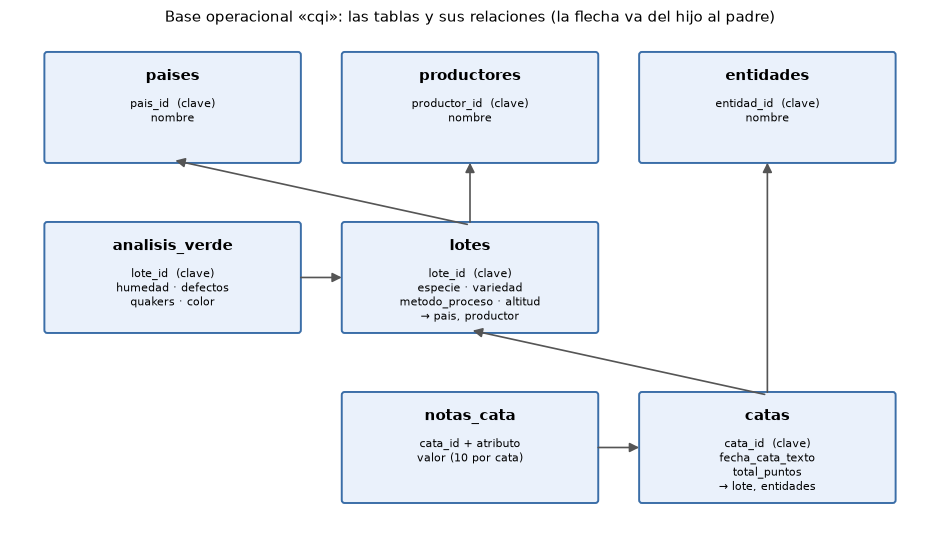

In [5]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

cajas = {   # nombre: (x, y, texto de columnas clave)
    'paises': (0.4, 3.2, 'pais_id  (clave)\nnombre'),
    'productores': (3.6, 3.2, 'productor_id  (clave)\nnombre'),
    'entidades': (6.8, 3.2, 'entidad_id  (clave)\nnombre'),
    'analisis_verde': (0.4, 1.5, 'lote_id  (clave)\nhumedad · defectos\nquakers · color'),
    'lotes': (3.6, 1.5, 'lote_id  (clave)\nespecie · variedad\nmetodo_proceso · altitud\n→ pais, productor'),
    'notas_cata': (3.6, -0.2, 'cata_id + atributo\nvalor (10 por cata)'),
    'catas': (6.8, -0.2, 'cata_id  (clave)\nfecha_cata_texto\ntotal_puntos\n→ lote, entidades'),
}
fig, ax = plt.subplots(figsize=(9.5, 5.6))
ancho, alto = 2.7, 1.05
for nombre, (x, y, texto) in cajas.items():
    ax.add_patch(FancyBboxPatch((x, y), ancho, alto, boxstyle='round,pad=0.03', fc='#EAF1FB', ec='#3B6EA8', lw=1.4))
    ax.text(x + ancho / 2, y + alto - 0.14, nombre, ha='center', va='top', fontweight='bold', fontsize=10.5)
    ax.text(x + ancho / 2, y + alto - 0.42, texto, ha='center', va='top', fontsize=8.2)
relaciones = [('lotes', 'paises'), ('lotes', 'productores'), ('catas', 'entidades'), ('analisis_verde', 'lotes'),
              ('catas', 'lotes'), ('notas_cata', 'catas')]
for hijo, padre in relaciones:
    xh, yh, _ = cajas[hijo]
    xp, yp, _ = cajas[padre]
    inicio = (xh + ancho / 2, yh + alto if yh < yp else yh)
    fin = (xp + ancho / 2, yp if yh < yp else yp + alto)
    if abs(yh - yp) < 0.2:
        inicio, fin = (xh if xh > xp else xh + ancho, yh + alto / 2), (xp + ancho if xh > xp else xp, yp + alto / 2)
    ax.add_patch(FancyArrowPatch(inicio, fin, arrowstyle='-|>', mutation_scale=14, color='#555555', lw=1.2))
ax.set_xlim(0, 9.9)
ax.set_ylim(-0.6, 4.5)
ax.axis('off')
ax.set_title('Base operacional «cqi»: las tablas y sus relaciones (la flecha va del hijo al padre)', fontsize=11)
plt.tight_layout()
plt.show()

Las reglas de la base están en `sql/operacional/01_crear_operacional.sql` (tablas, claves y restricciones) y
`02_poblar_operacional.sql` (cómo se llenan). **Ábrelos y léelos**: son SQL de verdad.

## 3. Crear la base operacional
La orden siguiente lee los CSV, comprueba que cada cata tiene exactamente **diez notas** (si no, no se puede normalizar sin perder
información), y llena las siete tablas de negocio. **No limpia nada**: la suciedad del origen se conserva a propósito, para que
RAW la reciba y MASTER la trate.

In [6]:
from cafe_mlops import operacional

lotes_cargados = operacional.crear_operacional(HASTA)
print(f'\nLotes cargados: {lotes_cargados:,}')

  OPERACIONAL: catas hasta 2016 (versión 1 de los datos)
  OPERACIONAL: paises                35 filas
  OPERACIONAL: entidades             26 filas
  OPERACIONAL: productores          621 filas
  OPERACIONAL: lotes              1,190 filas
  OPERACIONAL: analisis_verde     1,190 filas
  OPERACIONAL: catas              1,190 filas
  OPERACIONAL: notas_cata        11,900 filas

Lotes cargados: 1,190


## 4. Comprobar la simulación
Un pipeline no se da por bueno porque «no dio error»: se **comprueba**. Tres comprobaciones:
1. **Integridad referencial:** `PRAGMA foreign_key_check` lista las filas cuya clave foránea apunta a algo inexistente. Debe salir vacío.
2. **Diez notas por cata**, ni más ni menos.
3. **Sin pérdida:** al unir lotes, catas y análisis debe salir **exactamente** el número de lotes cargado.

In [7]:
con = db.conectar(config.DB_OPERACIONAL)

claves_rotas = con.execute('PRAGMA foreign_key_check').fetchall()
catas_sin_diez_notas = db.escalar(con, 'SELECT COUNT(*) FROM (SELECT cata_id FROM notas_cata GROUP BY cata_id HAVING COUNT(*) <> 10)')
lotes_unidos = db.escalar(con, 'SELECT COUNT(*) FROM lotes l JOIN catas c ON c.lote_id = l.lote_id JOIN analisis_verde a ON a.lote_id = l.lote_id')

assert claves_rotas == [], 'Hay claves foráneas rotas'
assert catas_sin_diez_notas == 0
assert lotes_unidos == lotes_cargados

pd.DataFrame({'resultado': {
    'claves foráneas rotas': len(claves_rotas),
    'catas que no tienen exactamente diez notas': catas_sin_diez_notas,
    'lotes que se reconstruyen al unir las tablas': lotes_unidos,
    'lotes cargados': lotes_cargados,
}})

,resultado
claves foráneas rotas,0
catas que no tienen exactamente diez notas,0
lotes que se reconstruyen al unir las tablas,1190
lotes cargados,1190


**¿Hasta qué año llegan los datos?** La fecha de cata está como texto («April 4th, 2015»); la función `anio_de_cata` del paquete saca el año.
La tabla cuenta los lotes por año y especie: con `HASTA = 2016` no hay ninguno posterior. Más adelante, el **año de la cata** será lo que
reparta los lotes entre entrenamiento, validación y prueba.

In [8]:
catas = pd.read_sql('SELECT c.fecha_cata_texto, l.especie FROM catas c JOIN lotes l ON l.lote_id = c.lote_id', con)
catas['año de cata'] = catas['fecha_cata_texto'].map(dataset.anio_de_cata)
pd.crosstab(catas['año de cata'], catas['especie'], margins=True, margins_name='total')

especie,Arabica,Robusta,total
año de cata,,,
2010,50,0,50
2011,83,0,83
2012,314,2,316
2013,153,2,155
2014,246,16,262
2015,195,2,197
2016,123,4,127
total,1164,26,1190


## 5. La suciedad que sigue ahí
Los datos reales traen errores. Aquí **no se corrigen**: se miden, para ver qué recibirá RAW y qué tendrá que tratar MASTER (cuaderno 01).

In [9]:
def cuantos(sql):
    return db.escalar(con, sql)


pd.DataFrame([
    ('Fechas de cata con espacios o saltos de línea sobrantes',
     cuantos("SELECT COUNT(*) FROM catas WHERE fecha_cata_texto <> TRIM(fecha_cata_texto, char(32, 9, 10, 13))"), 'MASTER las limpia'),
    (f'Altitud media fuera de {config.ALTITUD_MIN_M}–{config.ALTITUD_MAX_M} m',
     cuantos(f"SELECT COUNT(*) FROM lotes WHERE altitud_media_m IS NOT NULL AND (altitud_media_m < {config.ALTITUD_MIN_M} "
             f"OR altitud_media_m > {config.ALTITUD_MAX_M})"), 'MASTER la deja nula'),
    ('Humedad igual a 0 (parece «no medida»)', cuantos('SELECT COUNT(*) FROM analisis_verde WHERE humedad = 0'), 'MASTER la deja nula'),
    ('Catas con total 0 (incompletas)', cuantos('SELECT COUNT(*) FROM catas WHERE total_puntos IS NULL OR total_puntos <= 0'), 'MASTER las descarta'),
    ('Lotes sin variedad', cuantos('SELECT COUNT(*) FROM lotes WHERE variedad IS NULL'), 'sigue nula: el modelo la trata dentro'),
], columns=['qué pasa', 'cuántos lotes', 'qué hará el pipeline'])

,qué pasa,cuántos lotes,qué hará el pipeline
0,Fechas de cata con espacios o saltos de línea sobrantes,1,MASTER las limpia
1,Altitud media fuera de 100–4000 m,22,MASTER la deja nula
2,Humedad igual a 0 (parece «no medida»),231,MASTER la deja nula
3,Catas con total 0 (incompletas),0,MASTER las descarta
4,Lotes sin variedad,210,sigue nula: el modelo la trata dentro


## 6. Un lote visto como lo ve el sistema
Un lote se reparte entre varias tablas. Aquí el **lote 1**: sus datos de origen y análisis, y sus **diez notas de cata**.
Fíjate en la última línea: la **suma de las diez notas es la puntuación total**. Por eso las notas no pueden ser variables del modelo.

In [10]:
lote = pd.read_sql("""
    SELECT l.lote_id, l.especie, p.nombre AS pais, l.variedad, l.metodo_proceso, a.color, a.humedad, c.fecha_cata_texto, c.total_puntos
    FROM lotes l
    JOIN paises p ON p.pais_id = l.pais_id
    JOIN analisis_verde a ON a.lote_id = l.lote_id
    JOIN catas c ON c.lote_id = l.lote_id
    WHERE l.lote_id = 1""", con)
notas = pd.read_sql("""
    SELECT n.atributo, n.valor FROM notas_cata n JOIN catas c ON c.cata_id = n.cata_id WHERE c.lote_id = 1 ORDER BY n.rowid""", con)
display(lote.T.rename(columns={0: 'lote 1'}))
display(notas)
print(f'Suma de las diez notas: {notas["valor"].sum():.2f}   ·   Total.Cup.Points del lote: {lote.loc[0, "total_puntos"]:.2f}')
con.close()

,lote 1
lote_id,1
especie,Arabica
pais,Ethiopia
variedad,None
metodo_proceso,Washed / Wet
color,Green
humedad,0.12
fecha_cata_texto,"April 4th, 2015"
total_puntos,90.58


,atributo,valor
0,Aroma,8.67
1,Flavor,8.83
2,Aftertaste,8.67
3,Acidity,8.75
4,Body,8.50
5,Balance,8.42
6,Uniformity,10.00
7,Clean.Cup,10.00
8,Sweetness,10.00
9,Cupper.Points,8.75


Suma de las diez notas: 90.59   ·   Total.Cup.Points del lote: 90.58


## Resumen
- Hemos construido `cqi.db`, el **sistema operacional simulado**: siete tablas normalizadas, con claves y restricciones.
- Antes de usar el dato **comprobamos su huella**; después **comprobamos** las claves foráneas, las diez notas por cata y que no se pierde ningún lote.
- La suciedad del origen **sigue ahí** a propósito.
- Las diez notas suman el total: **no pueden usarse como variables** (lo demostraremos en el cuaderno 03).

**Siguiente:** el cuaderno **01** copia estas tablas a la capa RAW de la base analítica (la *ingesta*) y las depura en MASTER.

## Para practicar
1. ¿Por qué `notas_cata` tiene una fila por nota en vez de diez columnas? ¿Qué pasa con las notas de la robusta, que tienen otros nombres?
2. ¿Qué crees que pasaría con la tabla de lotes por año si llegaran los lotes de 2017 y 2018? (En el taller lo verás desde la terminal, con `--hasta 2018`.)